# k-nearest neighbors with scikit-learn

The k-nearest neighbors classifier (k-NN) learns no parameter: it keeps the training examples and, for a new point, lets its k nearest neighbors vote. This demo shows it on two data sets:

- two half-moons in two dimensions, to see the vote, then the effect of k on the boundary;
- the `wine` data set (13 chemical measurements), for feature scaling and for tuning k, the distance and the weights by cross-validation.

It ends with regression (the mean of the neighbors) and the two limitations of k-NN: the cost of prediction and high dimension.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_wine, make_classification, make_moons
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.model_selection import GridSearchCV, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

## Example data: two half-moons

`make_moons` draws 500 points of two classes shaped as interleaved half-moons; `noise=0.3` makes them overlap, so that no boundary separates them without errors. 30% of the points are kept aside for testing.

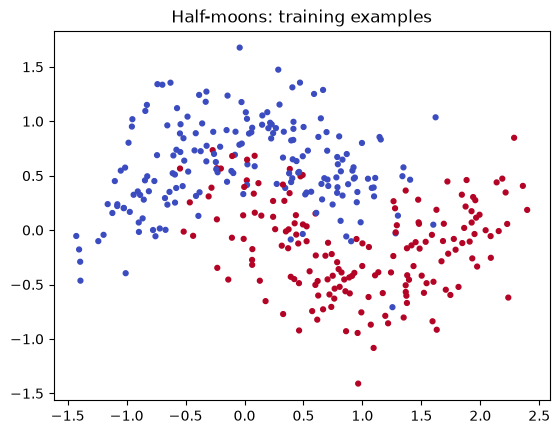

In [2]:
X, y = make_moons(n_samples=500, noise=0.3, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap="coolwarm", s=12)
plt.title("Half-moons: training examples")
plt.show()

## Predicting: the neighbors' vote

`fit` only stores the training examples (in a tree that speeds up the neighbor search). For a new point, `kneighbors` gives its k nearest neighbors and their distances; `predict` returns the majority class among them, `predict_proba` the share of each class in the vote.

In [3]:
model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train, y_train)

point = np.array([[0.5, 0.25]])
distances, indices = model.kneighbors(point)
print("distances of the 5 neighbors:", distances.round(2))
print("classes of the 5 neighbors:", y_train[indices])
print("predicted class:", model.predict(point))
print("share of each class:", model.predict_proba(point))

distances of the 5 neighbors: [[0.08 0.1  0.12 0.13 0.14]]
classes of the 5 neighbors: [[0 0 0 1 1]]
predicted class: [0]
share of each class: [[0.6 0.4]]


## Choosing k

k sets the bias-variance trade-off. For k from 1 to 200, we measure the accuracy on the training set and by 5-fold cross-validation, on the training examples only (the test set stays aside).

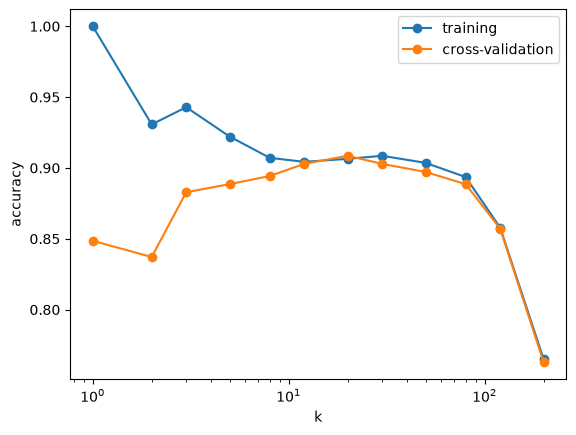

In [4]:
ks = [1, 2, 3, 5, 8, 12, 20, 30, 50, 80, 120, 200]
train_scores, cv_scores = [], []
for k in ks:
  scores = cross_validate(
    KNeighborsClassifier(n_neighbors=k),
    X_train,
    y_train,
    cv=5,
    return_train_score=True,
  )
  train_scores.append(scores["train_score"].mean())
  cv_scores.append(scores["test_score"].mean())

plt.plot(ks, train_scores, "o-", label="training")
plt.plot(ks, cv_scores, "o-", label="cross-validation")
plt.xscale("log")
plt.xlabel("k")
plt.ylabel("accuracy")
plt.legend()
plt.show()

- k = 1: no error on the training set (each point is its own neighbor), but a much lower cross-validation accuracy: the model learns the noise (high variance, overfitting).
- Large k (120, 200, out of 280 examples per fold): both curves drop together, the boundary no longer follows the shape of the moons (high bias). In the limit, k = n predicts the majority class everywhere (with uniform weights, the default).
- In between, a plateau around k = 10 to 50: that is where k is chosen.

The decision boundaries for three values of k, with the test accuracy:

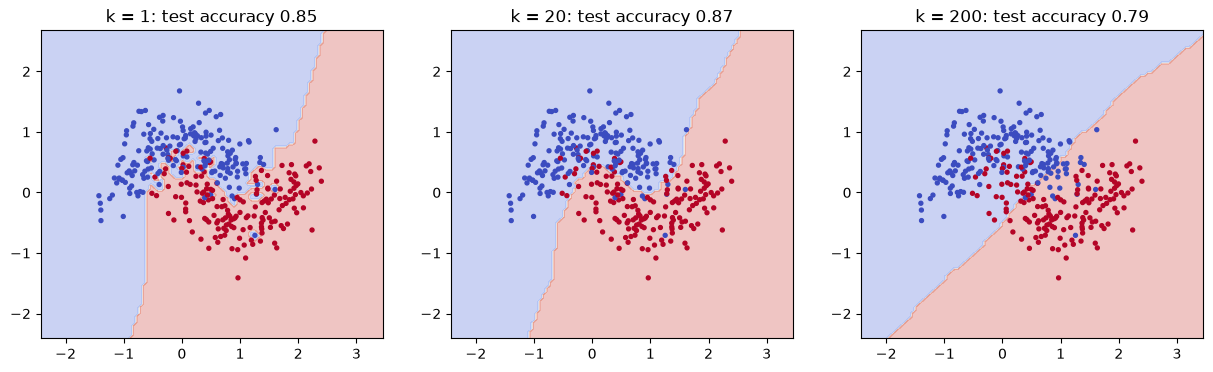

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, k in zip(axes, [1, 20, 200]):
  model = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
  DecisionBoundaryDisplay.from_estimator(
    model, X, ax=ax, cmap="coolwarm", alpha=0.3, response_method="predict"
  )
  ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap="coolwarm", s=8)
  ax.set_title(f"k = {k}: test accuracy {model.score(X_test, y_test):.2f}")
plt.show()

## Scaling: the `wine` data set

`load_wine` (shipped with scikit-learn) describes 178 wines from one region of Italy, made from three cultivars (the classes 0, 1 and 2). Each row is a wine, each column one of its 13 chemical measurements: alcohol, malic acid, magnesium, color intensity, proline… These measurements don't share a scale: proline is counted in hundreds, hue is around 1.

In [6]:
wine = load_wine(as_frame=True)
X, y = wine.data, wine.target
print(X.shape, "; wines per class:", y.value_counts().sort_index().tolist())
X.describe().loc[["mean", "std", "min", "max"]].T.round(2)

(178, 13) ; wines per class: [59, 71, 48]


,mean,std,min,max
alcohol,13.00,0.81,11.03,14.83
malic_acid,2.34,1.12,0.74,5.80
ash,2.37,0.27,1.36,3.23
alcalinity_of_ash,19.49,3.34,10.60,30.00
magnesium,99.74,14.28,70.00,162.00
total_phenols,2.30,0.63,0.98,3.88
flavanoids,2.03,1.00,0.34,5.08
nonflavanoid_phenols,0.36,0.12,0.13,0.66
proanthocyanins,1.59,0.57,0.41,3.58
color_intensity,5.06,2.32,1.28,13.00


A quarter of the wines is kept aside for testing, with the same class proportions (`stratify=y`).

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
  X, y, test_size=0.25, stratify=y, random_state=0
)

### Without scaling

k-NN on the raw measurements, then, for the first test wine, the share of each feature in the sum of squared differences to its 5 neighbors (the squared Euclidean distance).

In [8]:
raw_model = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
print(f"Test accuracy, without scaling: {raw_model.score(X_test, y_test):.3f}")

wine_0 = X_test.iloc[[0]]
_, indices = raw_model.kneighbors(wine_0)
squares = (X_train.iloc[indices[0]].to_numpy() - wine_0.to_numpy()) ** 2
share = pd.Series(squares.sum(axis=0) / squares.sum(), index=X.columns)
share.sort_values(ascending=False).head(3).round(3)

Test accuracy, without scaling: 0.667


proline            0.677
magnesium          0.204
color_intensity    0.052
dtype: float64

Proline and magnesium, the two measurements with the largest scales, make up most of the distance: the neighbors are chosen on them, the 11 other measurements barely count.

### With scaling

`StandardScaler` centers and scales each feature (mean 0, standard deviation 1). In a pipeline, its means and standard deviations are computed on the data given to `fit`, the training set only, then applied as is to the test set.

In [9]:
scaled_model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
scaled_model.fit(X_train, y_train)
print(f"Test accuracy, with scaling: {scaled_model.score(X_test, y_test):.3f}")

Test accuracy, with scaling: 0.933


## Tuning k, the distance and the weights

`GridSearchCV` tries every combination of the grid by 5-fold cross-validation, on the training set only:

- `n_neighbors`: k, from 1 to 30;
- `weights`: `"uniform"` (each neighbor has one vote) or `"distance"` (vote weighted by the inverse distance);
- `p`: the Minkowski distance, 1 for Manhattan, 2 for Euclidean.

The parameters of a pipeline's step are named `<step>__<parameter>`.

In [10]:
grid = GridSearchCV(
  make_pipeline(StandardScaler(), KNeighborsClassifier()),
  {
    "kneighborsclassifier__n_neighbors": list(range(1, 31)),
    "kneighborsclassifier__weights": ["uniform", "distance"],
    "kneighborsclassifier__p": [1, 2],
  },
  cv=5,
)
grid.fit(X_train, y_train)
print("Best parameters:", grid.best_params_)
print(f"Cross-validation accuracy: {grid.best_score_:.3f}")
print(f"Test accuracy: {grid.score(X_test, y_test):.3f}")

Best parameters: {'kneighborsclassifier__n_neighbors': 4, 'kneighborsclassifier__p': 1, 'kneighborsclassifier__weights': 'distance'}
Cross-validation accuracy: 0.962
Test accuracy: 1.000


The test set holds only 45 wines: one error more or less changes the accuracy by 2 points. Cross-validation chooses the parameters; the test set, kept aside, only measures the chosen model.

## Regression: the mean of the neighbors

`KNeighborsRegressor` predicts the mean of the targets of the k nearest neighbors. On a noisy sine, in one dimension, the prediction is a step function: following the noise for k = 1, smooth for k = 10, flattened for k = 50.

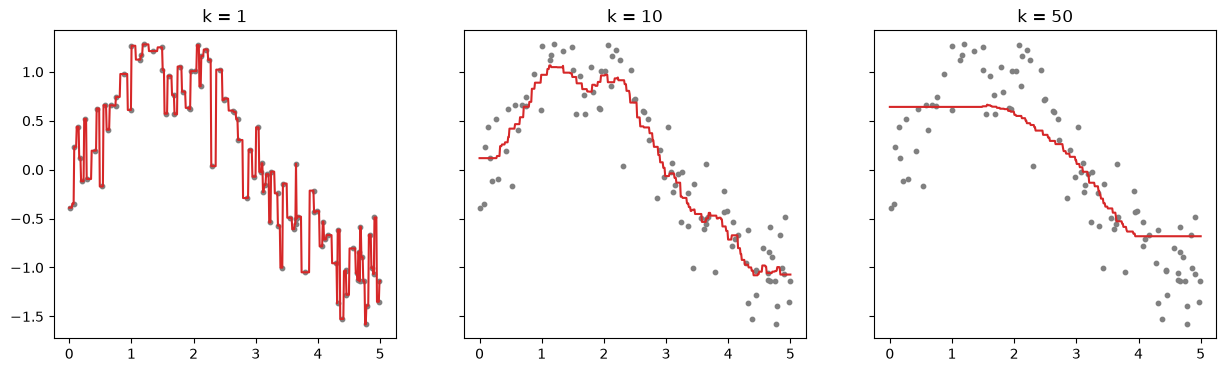

In [11]:
rng = np.random.default_rng(0)
x = np.sort(rng.uniform(0, 5, 100))[:, None]
target = np.sin(x).ravel() + rng.normal(0, 0.3, 100)
grid_x = np.linspace(0, 5, 500)[:, None]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, k in zip(axes, [1, 10, 50]):
  regressor = KNeighborsRegressor(n_neighbors=k).fit(x, target)
  ax.scatter(x, target, s=10, color="gray")
  ax.plot(grid_x, regressor.predict(grid_x), color="C3")
  ax.set_title(f"k = {k}")
plt.show()

## Limitations

### The cost of prediction

Training a k-NN means storing the data; predicting means computing the distance from the point to each of the n stored examples. Below, by brute force (`algorithm="brute"`, every distance computed), the training time and the time of 1,000 predictions, for 20 features and n from 10,000 to 1,000,000 examples. Trees (k-d, ball tree, which the default `"auto"` picks in low dimension) skip part of the computations, but less and less as the number of features grows.

In [12]:
for n in [10_000, 100_000, 1_000_000]:
  X_big, y_big = make_classification(n_samples=n + 1000, n_features=20, random_state=0)
  model = KNeighborsClassifier(n_neighbors=5, algorithm="brute")
  start = time.perf_counter()
  model.fit(X_big[:n], y_big[:n])
  fitted = time.perf_counter()
  model.predict(X_big[n:])
  predicted = time.perf_counter()
  print(
    f"n = {n:>9_}: training {fitted - start:.4f} s,"
    f" 1,000 predictions {predicted - fitted:.3f} s"
  )

n =    10_000: training 0.0025 s, 1,000 predictions 0.071 s
n =   100_000: training 0.0104 s, 1,000 predictions 0.712 s
n = 1_000_000: training 0.1485 s, 1,000 predictions 4.923 s


Training stays almost instant; prediction time grows like n. On large volumes, approximate neighbors (HNSW, FAISS) find the right neighbors almost always without computing every distance.

### High dimension

For 1,000 points drawn at random in a cube of dimension d, the ratio of the distance to the farthest point to the distance to the nearest one, seen from another random point: large, the nearest neighbor is much closer than the others; close to 1, all the points are almost at the same distance, and "nearest" no longer means much (the curse of dimensionality).

In [13]:
rng = np.random.default_rng(0)
for d in [2, 10, 100, 1000, 10_000]:
  points = rng.uniform(size=(1000, d))
  distances = np.linalg.norm(points - rng.uniform(size=d), axis=1)
  print(f"d = {d:>6}: farthest / nearest = {distances.max() / distances.min():.2f}")

d =      2: farthest / nearest = 135.62
d =     10: farthest / nearest = 4.48
d =    100: farthest / nearest = 1.39
d =   1000: farthest / nearest = 1.11
d =  10000: farthest / nearest = 1.04


Useless features have the same effect on a real data set: we add columns of pure noise to the 13 measurements of `wine`, then measure k-NN (k = 5, with scaling) by cross-validation. Each noise column weighs as much as a real measurement in the distance.

In [14]:
rng = np.random.default_rng(0)
for n_noise in [0, 10, 50, 200, 1000]:
  X_noisy = np.hstack([X.to_numpy(), rng.normal(size=(len(X), n_noise))])
  model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
  scores = cross_validate(model, X_noisy, y, cv=5)
  print(
    f"{n_noise:>4} noise columns:"
    f" cross-validation accuracy {scores['test_score'].mean():.3f}"
  )

   0 noise columns: cross-validation accuracy 0.949
  10 noise columns: cross-validation accuracy 0.944
  50 noise columns: cross-validation accuracy 0.860
 200 noise columns: cross-validation accuracy 0.697
1000 noise columns: cross-validation accuracy 0.512


With 1,000 noise columns, the accuracy falls to about one half, barely better than the 40% obtained by always predicting the most frequent class (71 wines out of 178): the 13 real measurements are drowned in the noise. Before k-NN in high dimension: select the useful features, or reduce the dimension (PCA).

## Key points

- A k-NN learns nothing: it keeps the examples and lets the k nearest vote (or averages them).
- k sets the bias-variance trade-off: small, it follows the noise; large, it smooths everything out. It is chosen by cross-validation, along with the distance and the weights.
- Features are scaled first, in a pipeline, otherwise the largest one alone decides the neighbors.
- Prediction costs n distance computations, and high dimension, like useless features, blurs the neighborhood.